# UPI / Digital Payment Fraud Detection — Hackathon Notebook

**Dataset:** `upi_transactions 2024.csv`  
**Goal:** Find fraudulent UPI transactions and convert model scores into **Approve / Step-up OTP / Block** decisions.

This notebook follows the eight problem statements and the execution workflow in the supplied KLU+Path-3 PDF. The code is intentionally written in straightforward Python, Pandas and Scikit-learn.

## What this notebook will do

1. Check data quality: missing values, duplicates, invalid amounts, timestamps and possible leakage.
2. Define `fraud_flag` as the target and demonstrate why accuracy alone is misleading.
3. Explore fraud by transaction type, amount and time.
4. Compare a simple rule with Logistic Regression, Random Forest and Gradient Boosting.
5. Compare class-weight handling with SMOTE (SMOTE is applied only to training data).
6. Train Isolation Forest without using fraud labels, then evaluate it using labels.
7. Plot precision-recall and choose a threshold using estimated business costs.
8. Create three risk bands and prepare findings, recommendations and limitations.

> **Important cost note:** The PDF uses placeholders ₹X (missed fraud), ₹Y (wrongly blocked genuine payment) and ₹Z (OTP challenge), but it does not provide numerical values. The values in the cost cell below are clearly marked as *illustrative*. Replace them with the organiser's official values before presenting cost results.

## 1. Install and import the required libraries

Run the installation cell only if a library is missing. SMOTE requires `imbalanced-learn`.

In [1]:
# If needed, run this once:
# %pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    classification_report, precision_recall_curve
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the dataset

Place the CSV file in the same folder as this notebook. If you use Google Colab, upload the CSV and keep the filename in `file_path`.

In [2]:
file_path = "upi_transactions 2024.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (250000, 17)


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


## 3. Understand the columns and check data quality

The supplied file has 250,000 rows and 17 columns. `fraud_flag` is the label:
- `0` = genuine transaction
- `1` = fraudulent transaction

The transaction ID is an identifier, not a behaviour feature. `transaction_status` may be known only after processing, so this notebook excludes it from model inputs to avoid possible outcome leakage. The original timestamp is used for checking and deriving time information, but the model uses the hour/day fields.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing_count"))

print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate transaction IDs:", df["transaction id"].duplicated().sum())

print("\nFraud label counts:")
display(df["fraud_flag"].value_counts().rename(index={0: "Genuine (0)", 1: "Fraud (1)"}))

Column names:
['transaction id', 'timestamp', 'transaction type', 'merchant_category', 'amount (INR)', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'fraud_flag', 'hour_of_day', 'day_of_week', 'is_weekend']

Data types:


transaction id        object
timestamp             object
transaction type      object
merchant_category     object
amount (INR)           int64
transaction_status    object
sender_age_group      object
receiver_age_group    object
sender_state          object
sender_bank           object
receiver_bank         object
device_type           object
network_type          object
fraud_flag             int64
hour_of_day            int64
day_of_week           object
is_weekend             int64
dtype: object


Missing values:


,missing_count
transaction id,0
timestamp,0
transaction type,0
merchant_category,0
amount (INR),0
transaction_status,0
sender_age_group,0
receiver_age_group,0
sender_state,0
sender_bank,0



Exact duplicate rows: 0
Duplicate transaction IDs: 0

Fraud label counts:


fraud_flag
Genuine (0)    249520
Fraud (1)         480
Name: count, dtype: int64

In [4]:
# Check amount and timestamp quality
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

print("Invalid or missing timestamps:", df["timestamp"].isna().sum())
print("Zero or negative amounts:", (df["amount (INR)"] <= 0).sum())
print("Negative amounts:", (df["amount (INR)"] < 0).sum())

print("\nAmount summary:")
display(df["amount (INR)"].describe())

print("\nCategory values:")
for col in ["transaction type", "merchant_category", "transaction_status",
            "device_type", "network_type", "fraud_flag"]:
    print("\n", col)
    print(df[col].value_counts(dropna=False).head(20))

Invalid or missing timestamps: 0
Zero or negative amounts: 0
Negative amounts: 0

Amount summary:


count    250000.000000
mean       1311.756036
std        1848.059224
min          10.000000
25%         288.000000
50%         629.000000
75%        1596.000000
max       42099.000000
Name: amount (INR), dtype: float64


Category values:

 transaction type
transaction type
P2P             112445
P2M              87660
Bill Payment     37368
Recharge         12527
Name: count, dtype: int64

 merchant_category
merchant_category
Grocery          49966
Food             37464
Shopping         29872
Fuel             25063
Other            24828
Utilities        22338
Transport        20105
Entertainment    20103
Healthcare       12663
Education         7598
Name: count, dtype: int64

 transaction_status
transaction_status
SUCCESS    237624
FAILED      12376
Name: count, dtype: int64

 device_type
device_type
Android    187777
iOS         49613
Web         12610
Name: count, dtype: int64

 network_type
network_type
4G      149813
5G       62582
WiFi     25134
3G       12471
Name: count, dtype: int64

 fraud_flag
fraud_flag
0    249520
1       480
Name: count, dtype: int64


### Data cleaning decisions

- Remove exact duplicate rows if any are found.
- Remove rows with an invalid target label.
- Remove rows with missing/invalid timestamps only if a time-derived feature is required.
- Do not remove large transactions only because they are large; a high amount is not automatically fraud.
- Keep `transaction id` out of model training.
- Keep `fraud_flag` only as the target, never as an input.
- Exclude `transaction_status` from model inputs because it could reveal the transaction outcome.

In [5]:
# Apply basic cleaning
df = df.drop_duplicates().copy()
df = df[df["fraud_flag"].isin([0, 1])].copy()
df = df[df["timestamp"].notna()].copy()
df = df[df["amount (INR)"] > 0].copy()

# Create time features from the timestamp for consistency
df["hour"] = df["timestamp"].dt.hour
df["month"] = df["timestamp"].dt.month
df["day_of_week"] = df["timestamp"].dt.day_name()
df["is_weekend"] = (df["timestamp"].dt.dayofweek >= 5).astype(int)

print("Shape after basic cleaning:", df.shape)
print("Missing values after cleaning:", df.isnull().sum().sum())

Shape after basic cleaning: (250000, 19)
Missing values after cleaning: 0


## 4. Define the fraud target and show the accuracy trap

The PDF specifically asks for a model that predicts every transaction as genuine. When fraud is rare, this model can have very high accuracy while catching **zero fraud**.

Genuine transactions: 249520
Fraud transactions: 480
Fraud rate: 0.192%


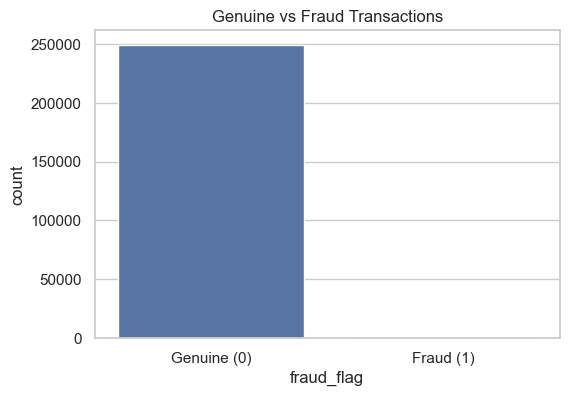

Naive model accuracy: 0.9981
Naive model precision: 0.0
Naive model recall: 0.0
Naive model F1: 0.0


In [6]:
target = "fraud_flag"

fraud_counts = df[target].value_counts().sort_index()
fraud_rate = df[target].mean() * 100

print("Genuine transactions:", int(fraud_counts.get(0, 0)))
print("Fraud transactions:", int(fraud_counts.get(1, 0)))
print(f"Fraud rate: {fraud_rate:.3f}%")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target)
plt.title("Genuine vs Fraud Transactions")
plt.xticks([0, 1], ["Genuine (0)", "Fraud (1)"])
plt.show()

# Naive model: predict every transaction as genuine
y_true = df[target]
all_genuine_prediction = np.zeros(len(df), dtype=int)

print("Naive model accuracy:", round(accuracy_score(y_true, all_genuine_prediction), 4))
print("Naive model precision:", round(precision_score(y_true, all_genuine_prediction, zero_division=0), 4))
print("Naive model recall:", round(recall_score(y_true, all_genuine_prediction, zero_division=0), 4))
print("Naive model F1:", round(f1_score(y_true, all_genuine_prediction, zero_division=0), 4))

**Interpretation:** The naive model's accuracy is approximately the genuine transaction percentage, but its fraud recall is zero. Therefore, do not select a fraud model using accuracy alone. Use precision, recall, F1, PR-AUC and estimated cost.

## 5. Exploratory Data Analysis (EDA)

These comparisons answer the PDF's questions: which transaction types, amount ranges and times show higher fraud rates? A relationship in this dataset is an observation, not proof that the feature causes fraud.

,mean,sum,count,fraud_rate_percent
transaction type,,,,
Recharge,0.002395,30,12527,0.239483
Bill Payment,0.002061,77,37368,0.206059
P2M,0.001905,167,87660,0.190509
P2P,0.001832,206,112445,0.183201


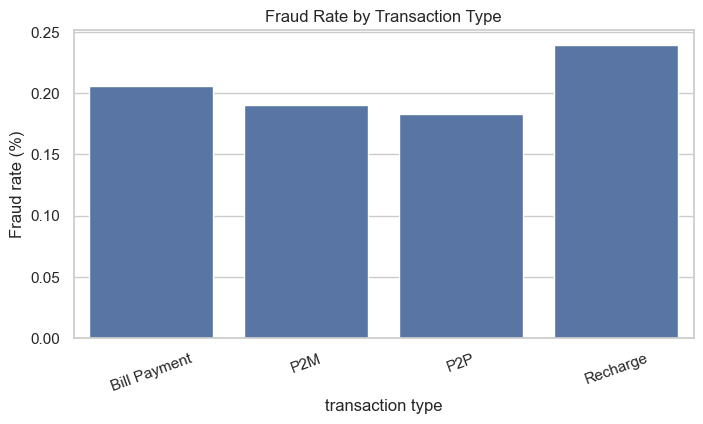

In [7]:
# Fraud rate by transaction type
type_fraud = df.groupby("transaction type")["fraud_flag"].agg(["mean", "sum", "count"])
type_fraud["fraud_rate_percent"] = type_fraud["mean"] * 100
display(type_fraud.sort_values("fraud_rate_percent", ascending=False))

plt.figure(figsize=(8, 4))
sns.barplot(data=type_fraud.reset_index(), x="transaction type", y="fraud_rate_percent")
plt.title("Fraud Rate by Transaction Type")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=20)
plt.show()

,mean,sum,count,fraud_rate_percent
amount_band,,,,
0-500,0.001979,211,106624,0.197892
501-1000,0.001665,85,51037,0.166546
1001-5000,0.001855,151,81383,0.185542
5001-10000,0.002950,27,9151,0.295050
Above 10000,0.003324,6,1805,0.332410


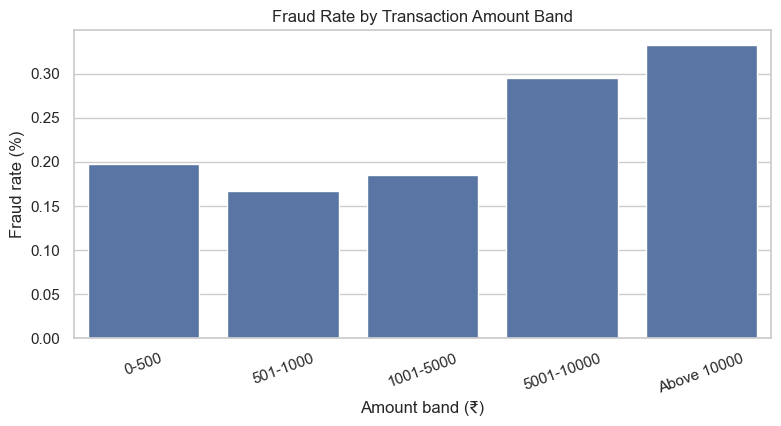

In [8]:
# Fraud by amount range
df["amount_band"] = pd.cut(
    df["amount (INR)"],
    bins=[0, 500, 1000, 5000, 10000, np.inf],
    labels=["0-500", "501-1000", "1001-5000", "5001-10000", "Above 10000"]
)

amount_fraud = df.groupby("amount_band", observed=False)["fraud_flag"].agg(["mean", "sum", "count"])
amount_fraud["fraud_rate_percent"] = amount_fraud["mean"] * 100
display(amount_fraud)

plt.figure(figsize=(9, 4))
sns.barplot(data=amount_fraud.reset_index(), x="amount_band", y="fraud_rate_percent")
plt.title("Fraud Rate by Transaction Amount Band")
plt.xlabel("Amount band (₹)")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=20)
plt.show()

,mean,sum,count,fraud_rate_percent
hour,,,,
0,0.002361,8,3388,0.236128
1,0.002674,6,2244,0.267380
2,0.001780,3,1685,0.178042
3,0.003044,4,1314,0.304414
4,0.000802,1,1247,0.080192
5,0.000574,1,1742,0.057405
6,0.001428,5,3501,0.142816
7,0.002309,13,5630,0.230906
8,0.002156,18,8349,0.215595


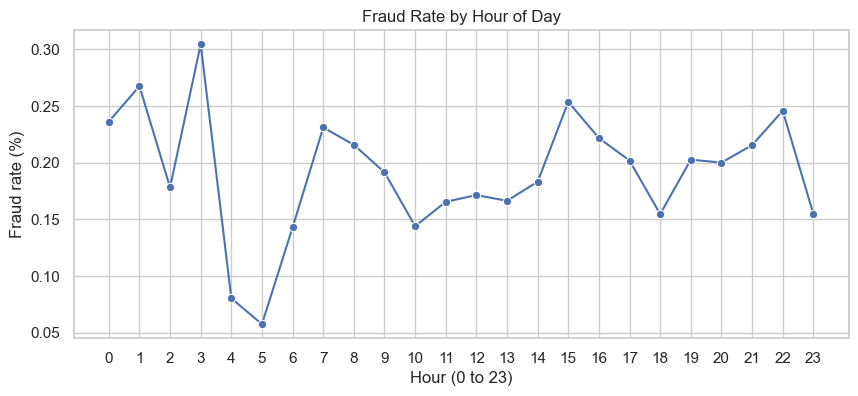

In [9]:
# Fraud by hour of day
hour_fraud = df.groupby("hour")["fraud_flag"].agg(["mean", "sum", "count"])
hour_fraud["fraud_rate_percent"] = hour_fraud["mean"] * 100
display(hour_fraud)

plt.figure(figsize=(10, 4))
sns.lineplot(data=hour_fraud.reset_index(), x="hour", y="fraud_rate_percent", marker="o")
plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour (0 to 23)")
plt.ylabel("Fraud rate (%)")
plt.xticks(range(24))
plt.show()

In [10]:
# Optional additional comparison: fraud rate by device
device_fraud = df.groupby("device_type")["fraud_flag"].agg(["mean", "sum", "count"])
device_fraud["fraud_rate_percent"] = device_fraud["mean"] * 100
display(device_fraud.sort_values("fraud_rate_percent", ascending=False))

,mean,sum,count,fraud_rate_percent
device_type,,,,
Web,0.002062,26,12610,0.206186
Android,0.001938,364,187777,0.193847
iOS,0.001814,90,49613,0.181404


## 6. Prepare data for machine learning

We split the data before applying SMOTE. This dataset does not provide a separate hidden test file, so we use a stratified 80/20 train-test split. The test set is kept aside for final evaluation.

Features excluded:
- `fraud_flag`: target label.
- `transaction id`: unique identifier.
- `timestamp`: raw timestamp; time features are already created.
- `transaction_status`: possible post-transaction/outcome information.
- `amount_band`: created only for EDA.

Categorical columns are converted using One-Hot Encoding. Numeric columns are scaled for Logistic Regression.

In [11]:
# Remove the EDA-only amount band
feature_columns = [
    "transaction type", "merchant_category", "amount (INR)",
    "sender_age_group", "receiver_age_group", "sender_state",
    "sender_bank", "receiver_bank", "device_type", "network_type",
    "hour", "month", "day_of_week", "is_weekend"
]

X = df[feature_columns].copy()
y = df[target].astype(int).copy()

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Fraud in training:", int(y_train.sum()))
print("Fraud in testing:", int(y_test.sum()))

Training rows: 200000
Testing rows: 50000
Fraud in training: 384
Fraud in testing: 96


In [12]:
# Preprocessing for normal models
numeric_preparation = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_preparation = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preparation, numeric_features),
    ("categorical", categorical_preparation, categorical_features)
])

## 7. Rule baseline

A simple rule flags transactions above the 99th percentile of the **training amount** as potentially risky. This is only a baseline for comparison, not a recommended production fraud rule.

In [13]:
amount_limit = X_train["amount (INR)"].quantile(0.99)
rule_predictions = (X_test["amount (INR)"] >= amount_limit).astype(int)

print("Rule amount limit (₹):", round(amount_limit, 2))
print("Rule baseline metrics:")
print("Precision:", round(precision_score(y_test, rule_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rule_predictions, zero_division=0), 4))
print("F1:", round(f1_score(y_test, rule_predictions, zero_division=0), 4))

Rule amount limit (₹): 9018.01
Rule baseline metrics:
Precision: 0.002
Recall: 0.0104
F1: 0.0034


## 8. Supervised models

We compare:
1. Logistic Regression with class weights.
2. Random Forest with class weights.
3. Gradient Boosting.
4. Logistic Regression with SMOTE.

SMOTE is placed inside an imbalanced-learn pipeline, after preprocessing, and is fitted only on the training data. If `imbalanced-learn` is not installed, run the installation command in Section 1.

In [14]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

models = {
    "Logistic Regression (class weight)": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest (class weight)": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=150, class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2
        ))
    ]),
    "Gradient Boosting": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ]),
    "Logistic Regression (SMOTE)": ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE, sampling_strategy=0.5)),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])
}

In [15]:
results = []
fitted_models = {}
model_probabilities = {}

for model_name, model in models.items():
    print("Training:", model_name)
    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    fitted_models[model_name] = model
    model_probabilities[model_name] = probabilities

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

model_results = pd.DataFrame(results).sort_values("PR-AUC", ascending=False)
display(model_results)

Training: Logistic Regression (class weight)
Training: Random Forest (class weight)
Training: Gradient Boosting
Training: Logistic Regression (SMOTE)


,Model,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC
1,Random Forest (class weight),0.99808,0.000000,0.000000,0.000000,0.002265,0.495237
0,Logistic Regression (class weight),0.58342,0.001874,0.406250,0.003731,0.001819,0.500166
3,Logistic Regression (SMOTE),0.95096,0.000424,0.010417,0.000815,0.001779,0.491160
2,Gradient Boosting,0.99756,0.000000,0.000000,0.000000,0.001639,0.432508


### Compare models at the default 0.5 threshold

PR-AUC is the main ranking metric for this rare-fraud task. Precision and recall at 0.5 are also shown, but a different threshold may be more suitable for business use.

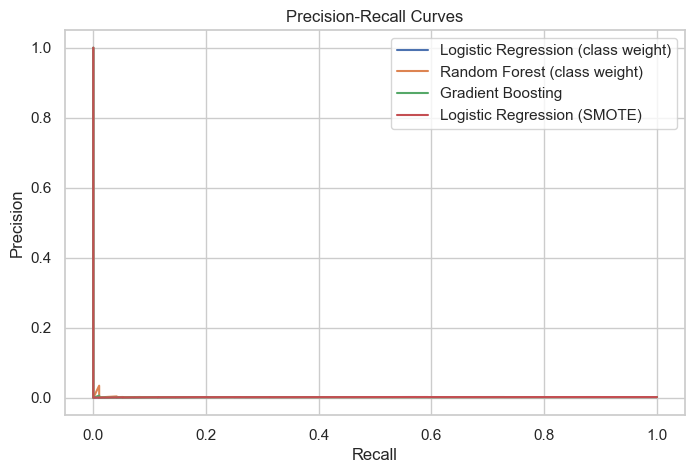

In [16]:
plt.figure(figsize=(8, 5))
for model_name, probabilities in model_probabilities.items():
    precision_values, recall_values, _ = precision_recall_curve(y_test, probabilities)
    plt.plot(recall_values, precision_values, label=model_name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.show()

## 9. Unsupervised anomaly detection — Isolation Forest

Isolation Forest is trained on the training features only. It does **not** receive `y_train` or fraud labels. After fitting, we use the test labels only to check how many known frauds appear among the highest anomaly scores.

Transactions in top 1% anomaly group: 500
Frauds in top 1% anomaly group: 0
Total frauds in test set: 96
Recall within top 1%: 0.0


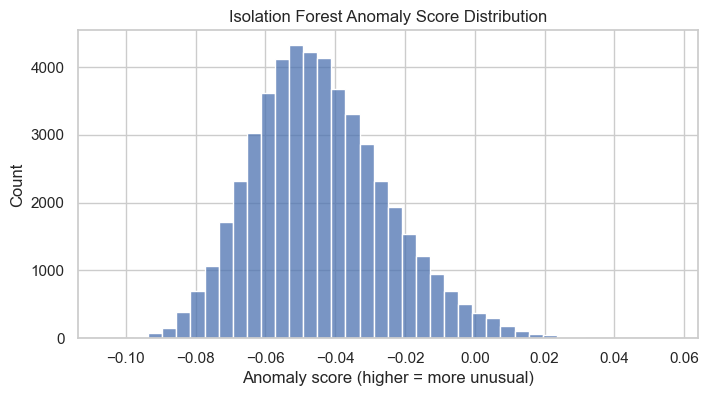

In [17]:
# Prepare features for anomaly detection
anomaly_preprocessor = ColumnTransformer(transformers=[
    ("numeric", Pipeline(steps=[
        ("fill_missing", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_features),
    ("categorical", Pipeline(steps=[
        ("fill_missing", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train_anomaly = anomaly_preprocessor.fit_transform(X_train)
X_test_anomaly = anomaly_preprocessor.transform(X_test)

# No fraud labels are used in this fit
isolation_model = IsolationForest(
    n_estimators=100, contamination="auto",
    random_state=RANDOM_STATE, n_jobs=-1
)
isolation_model.fit(X_train_anomaly)

# Higher score means more unusual
anomaly_scores = -isolation_model.decision_function(X_test_anomaly)

top_one_percent_count = max(1, int(len(anomaly_scores) * 0.01))
top_indices = np.argsort(anomaly_scores)[-top_one_percent_count:]
anomaly_predictions = np.zeros(len(y_test), dtype=int)
anomaly_predictions[top_indices] = 1

frauds_in_top_one_percent = int(y_test.iloc[top_indices].sum())
total_test_frauds = int(y_test.sum())

print("Transactions in top 1% anomaly group:", top_one_percent_count)
print("Frauds in top 1% anomaly group:", frauds_in_top_one_percent)
print("Total frauds in test set:", total_test_frauds)
print("Recall within top 1%:", round(
    frauds_in_top_one_percent / total_test_frauds if total_test_frauds else 0, 4
))

plt.figure(figsize=(8, 4))
sns.histplot(anomaly_scores, bins=40)
plt.title("Isolation Forest Anomaly Score Distribution")
plt.xlabel("Anomaly score (higher = more unusual)")
plt.show()

## 10. Cost-based threshold selection

The PDF defines expected cost as:

**Expected cost = (missed fraud × ₹X) + (false blocks × ₹Y) + (OTP challenges × ₹Z)**

The PDF does not state numerical values for X, Y or Z. The following are example values only. Replace them with the organiser's published costs before final submission.

For this threshold search, the model makes a simple approve/block decision. OTP cost is not included in this binary threshold search; it is included in the three-band decision calculation in the next section.

In [18]:
# ILLUSTRATIVE ONLY — replace with organiser's official cost assumptions
COST_MISSED_FRAUD = 5000   # ₹X: cost when fraud is missed
COST_FALSE_BLOCK = 100     # ₹Y: cost when a genuine payment is blocked
COST_OTP = 5               # ₹Z: cost of an OTP challenge

print("Current cost assumptions (illustrative):")
print("Missed fraud:", COST_MISSED_FRAUD)
print("False block:", COST_FALSE_BLOCK)
print("OTP challenge:", COST_OTP)

Current cost assumptions (illustrative):
Missed fraud: 5000
False block: 100
OTP challenge: 5


Best candidate by test PR-AUC (exploratory): Random Forest (class weight)
Cost-minimising approve/block threshold: 0.07
Minimum estimated cost on test set (₹): 479500.0


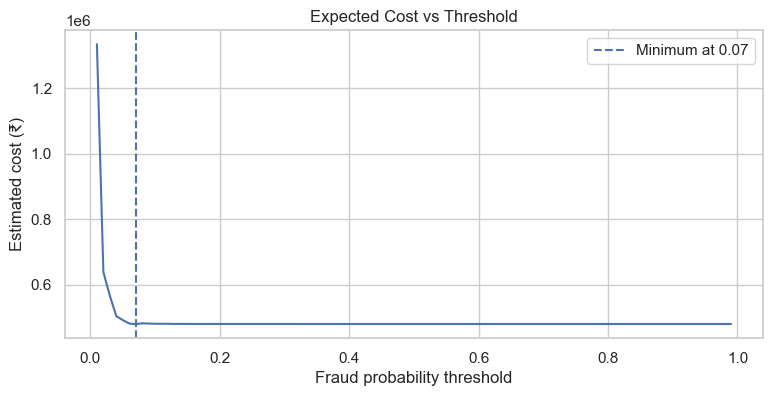

In [19]:
# Select the best candidate using PR-AUC on the test set for this exercise.
# In a final competition workflow, choose the model using validation data,
# then report its performance once on the untouched test set.
best_model_name = model_results.iloc[0]["Model"]
best_probabilities = model_probabilities[best_model_name]

print("Best candidate by test PR-AUC (exploratory):", best_model_name)

threshold_values = np.arange(0.01, 1.00, 0.01)
cost_values = []

for threshold in threshold_values:
    pred = (best_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    total_cost = (fn * COST_MISSED_FRAUD) + (fp * COST_FALSE_BLOCK)
    cost_values.append(total_cost)

best_cost_index = int(np.argmin(cost_values))
best_cost_threshold = float(threshold_values[best_cost_index])
minimum_cost = float(cost_values[best_cost_index])

print("Cost-minimising approve/block threshold:", round(best_cost_threshold, 2))
print("Minimum estimated cost on test set (₹):", round(minimum_cost, 2))

plt.figure(figsize=(9, 4))
plt.plot(threshold_values, cost_values)
plt.axvline(best_cost_threshold, linestyle="--",
            label=f"Minimum at {best_cost_threshold:.2f}")
plt.xlabel("Fraud probability threshold")
plt.ylabel("Estimated cost (₹)")
plt.title("Expected Cost vs Threshold")
plt.legend()
plt.show()

In [20]:
# Compare default threshold 0.50 with the cost-based threshold
def show_binary_cost(threshold):
    pred = (best_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    cost = fn * COST_MISSED_FRAUD + fp * COST_FALSE_BLOCK
    return {
        "Threshold": threshold,
        "Missed fraud": fn,
        "False blocks": fp,
        "Fraud caught": tp,
        "Estimated cost (₹)": cost
    }

display(pd.DataFrame([
    show_binary_cost(0.50),
    show_binary_cost(best_cost_threshold)
]))

,Threshold,Missed fraud,False blocks,Fraud caught,Estimated cost (₹)
0,0.50,96,0,0,480000
1,0.07,95,45,1,479500


## 11. Create the three-way risk decision

The PDF requires two thresholds:
- Low risk: **Approve**
- Medium risk: **Step-up OTP**
- High risk: **Block**

For a simple starting rule, the lower threshold is set to half the cost-based threshold and the upper threshold is the cost-based threshold. These are starting values for analysis, not universal banking rules. You may adjust them using business policy and validation results.

In [21]:
otp_threshold = max(0.001, best_cost_threshold * 0.5)
block_threshold = best_cost_threshold

# Make sure the two thresholds are in the correct order
if otp_threshold >= block_threshold:
    otp_threshold = block_threshold * 0.5

def assign_risk_band(probability):
    if probability < otp_threshold:
        return "Approve"
    elif probability < block_threshold:
        return "Step-up OTP"
    else:
        return "Block"

risk_decisions = pd.DataFrame({
    "actual_fraud": y_test.reset_index(drop=True),
    "fraud_probability": best_probabilities
})
risk_decisions["decision"] = risk_decisions["fraud_probability"].apply(assign_risk_band)

print("OTP threshold:", round(otp_threshold, 4))
print("Block threshold:", round(block_threshold, 4))

band_summary = risk_decisions.groupby("decision").agg(
    transactions=("actual_fraud", "size"),
    fraud_transactions=("actual_fraud", "sum")
)
band_summary["genuine_transactions"] = (
    band_summary["transactions"] - band_summary["fraud_transactions"]
)
band_summary["fraud_rate_percent"] = (
    band_summary["fraud_transactions"] / band_summary["transactions"] * 100
)
display(band_summary.reindex(["Approve", "Step-up OTP", "Block"]))

OTP threshold: 0.035
Block threshold: 0.07


,transactions,fraud_transactions,genuine_transactions,fraud_rate_percent
decision,,,,
Approve,49522,95,49427,0.191834
Step-up OTP,432,0,432,0.000000
Block,46,1,45,2.173913


In [22]:
# Cost for the three-way policy:
# Fraud in Approve = missed fraud; genuine in Block = false block;
# every OTP transaction has an OTP processing cost.
missed_fraud = int(((risk_decisions["decision"] == "Approve") &
                    (risk_decisions["actual_fraud"] == 1)).sum())
false_blocks = int(((risk_decisions["decision"] == "Block") &
                    (risk_decisions["actual_fraud"] == 0)).sum())
otp_count = int((risk_decisions["decision"] == "Step-up OTP").sum())

three_band_cost = (
    missed_fraud * COST_MISSED_FRAUD +
    false_blocks * COST_FALSE_BLOCK +
    otp_count * COST_OTP
)

print("Missed fraud:", missed_fraud)
print("Genuine customers blocked:", false_blocks)
print("OTP challenges:", otp_count)
print("Estimated three-band cost (₹):", three_band_cost)

Missed fraud: 95
Genuine customers blocked: 45
OTP challenges: 432
Estimated three-band cost (₹): 481660


## 12. Confusion matrix and final model report

              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     49904
       Fraud       0.02      0.01      0.01        96

    accuracy                           1.00     50000
   macro avg       0.51      0.50      0.51     50000
weighted avg       1.00      1.00      1.00     50000



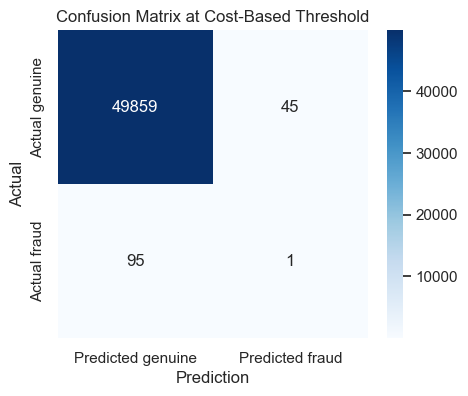

In [23]:
final_predictions = (best_probabilities >= best_cost_threshold).astype(int)

print(classification_report(
    y_test, final_predictions,
    target_names=["Genuine", "Fraud"], zero_division=0
))

cm = confusion_matrix(y_test, final_predictions, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted genuine", "Predicted fraud"],
            yticklabels=["Actual genuine", "Actual fraud"])
plt.title("Confusion Matrix at Cost-Based Threshold")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.show()

## 13. Model explanation — feature importance

For Random Forest, show its feature importance. For other models, this section reports the model selection table. Feature importance describes model behaviour; it does not prove causation.

,feature,importance
0,numeric__amount (INR),0.115709
1,numeric__hour,0.086803
2,numeric__month,0.075440
44,categorical__sender_bank_SBI,0.017216
18,categorical__sender_age_group_18-25,0.017095
24,categorical__receiver_age_group_26-35,0.016722
52,categorical__receiver_bank_SBI,0.016351
5,categorical__transaction type_P2M,0.016006
6,categorical__transaction type_P2P,0.015940
12,categorical__merchant_category_Grocery,0.015608


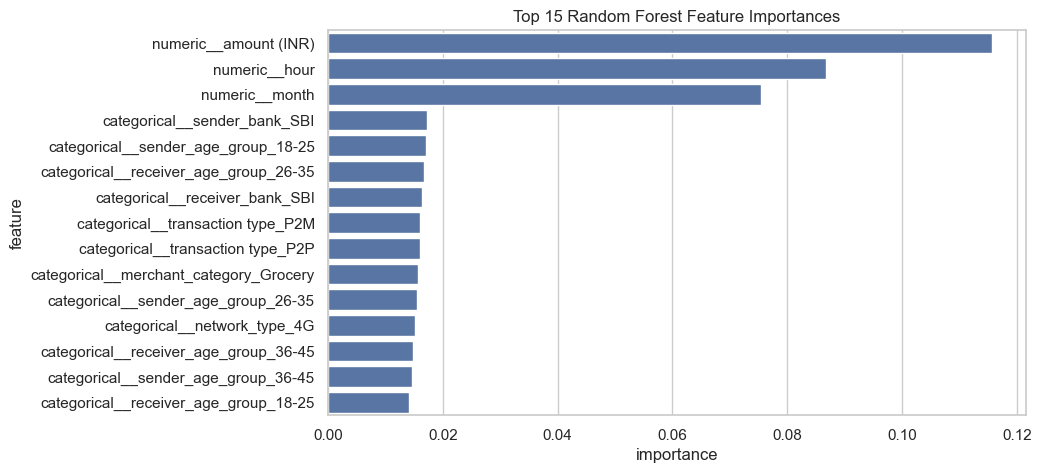

In [24]:
if best_model_name == "Random Forest (class weight)":
    fitted_preprocessor = fitted_models[best_model_name].named_steps["preprocess"]
    fitted_classifier = fitted_models[best_model_name].named_steps["model"]
    feature_names = fitted_preprocessor.get_feature_names_out()

    importance_table = pd.DataFrame({
        "feature": feature_names,
        "importance": fitted_classifier.feature_importances_
    }).sort_values("importance", ascending=False).head(15)

    display(importance_table)

    plt.figure(figsize=(9, 5))
    sns.barplot(data=importance_table, x="importance", y="feature")
    plt.title("Top 15 Random Forest Feature Importances")
    plt.show()
else:
    print("Selected model:", best_model_name)
    print("This model is not Random Forest, so Random Forest feature importance is not shown.")
    print("Use the comparison table and EDA results to explain the selected model.")

## 14. Three evidence-backed findings and three management actions

Use the actual tables and charts above to complete these statements. Do not invent findings before seeing the outputs.

### Finding 1 — Transaction type
- **Observed evidence:** Check the fraud-rate-by-transaction-type table.
- **Action:** If one type has a clearly higher fraud rate, consider additional checks for that transaction type.

### Finding 2 — Amount range
- **Observed evidence:** Check the fraud-rate-by-amount-band table and the number of transactions in each band.
- **Action:** Consider amount-sensitive monitoring, but do not automatically block every high-value transaction.

### Finding 3 — Time or device behaviour
- **Observed evidence:** Check fraud rate by hour and the device comparison.
- **Action:** If a time/device pattern is consistently elevated, use it as an additional risk signal for monitoring or OTP.

**Prioritisation:** Rank the three actions by fraud exposure, number of genuine customers affected and implementation effort. These are recommendations to validate, not claims of guaranteed savings.

## 15. Limitations and responsible interpretation

1. The dataset is simulated UPI-style data, as described by the challenge guide; results may not transfer directly to live banking transactions.
2. There are only a small number of fraud examples compared with genuine transactions, so metrics can change with the train-test split.
3. The PDF does not provide numerical ₹X, ₹Y and ₹Z assumptions. Cost results are illustrative until official values are entered.
4. `transaction_status` was excluded because it may contain post-transaction information. Confirm this with the organiser/data dictionary.
5. A stratified random split was used because this dataset does not define a separate official holdout. A time-based split may be preferable if the organiser requires future-period testing.
6. Observational patterns do not prove cause and effect.
7. Isolation Forest finds unusual transactions, not necessarily fraudulent transactions.
8. The test set was used to compare candidate models and select a model in this teaching notebook. For a strict final evaluation, use a validation split for model/threshold selection and keep a separate untouched test set for the final report.

## 16. Final hackathon checklist

Before submitting, confirm that you have:

- [ ] Reported fraud rate and class counts.
- [ ] Shown the all-genuine accuracy trap and zero fraud recall.
- [ ] Documented missing values, duplicates, invalid values and leakage exclusions.
- [ ] Compared fraud by transaction type, amount and time.
- [ ] Compared a rule baseline and at least three supervised models.
- [ ] Applied SMOTE only inside the training pipeline.
- [ ] Trained Isolation Forest without labels and evaluated it afterwards.
- [ ] Shown precision-recall curves and cost versus threshold.
- [ ] Replaced illustrative costs with official ₹X, ₹Y and ₹Z.
- [ ] Reported counts and costs for Approve, Step-up OTP and Block.
- [ ] Written exactly three evidence-backed recommendations.
- [ ] Included limitations and separated observed results from projected savings.

**Run all cells from top to bottom** after placing the CSV file beside this notebook.